<a href="https://colab.research.google.com/github/gcetin74/merhaba/blob/main/depresyon_renew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

file_path = '/content/Student_Depression_Dataset.csv'
assert os.path.exists(file_path), "CSV yüklenmemiş: Colab → Dosyalar → Yükle"
df = pd.read_csv(file_path)

# Katı boyut kontrolü yerine bilgilendirme mesajı verelim
if df.shape == (4464, 13):
    print("Orijinal veri seti başarıyla yüklendi:", df.shape)
else:
    print(f"Bilgi: Farklı boyutta bir veri seti yüklendi: {df.shape} (Örnek veya özelleştirilmiş veri seti)")

display(df.info())
display(df.head())

Orijinal veri seti başarıyla yüklendi: (4464, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


None

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


## 1. Betimsel İstatistikler (Descriptive Statistics)
Sayısal ve kategorik değişkenlerin genel dağılımlarını inceliyoruz.

In [27]:
# Sayısal değişkenlerin betimsel istatistikleri
print("Sayısal Değişkenlerin Özeti:")
display(df.describe().T)

# Kategorik değişkenlerin frekansları
if 'Gender' in df.columns:
    print("\nCinsiyet Dağılımı:")
    display(df['Gender'].value_counts())

if 'Depression' in df.columns:
    print("\nDepresyon Durumu Dağılımı (0: Hayır, 1: Evet / Veya Sınıflar):")
    display(df['Depression'].value_counts())

Sayısal Değişkenlerin Özeti:


,count,mean,std,min,25%,50%,75%,max
Age,4464.0,22.619176,2.022980,17.00,21.00,23.00,24.0,28.0
Current_semester,4464.0,5.401210,2.578476,0.00,3.00,5.00,7.0,13.0
CGPA,4464.0,3.412753,0.385605,2.25,3.15,3.49,3.7,4.0
Cost_without_study,4464.0,11242.978271,6640.144019,0.00,6100.00,9500.00,15439.0,32000.0



Cinsiyet Dağılımı:


,count
Gender,
Female,2462
Male,2002



Depresyon Durumu Dağılımı (0: Hayır, 1: Evet / Veya Sınıflar):


,count
Depression,
No,3263
Yes,1201


## 2. Grup Karşılaştırması (Group Comparison)
Cinsiyete (Gender) göre CGPA (Akademik Başarı) puanlarının farklılaşıp farklılaşmadığını incelemek için parametrik olmayan Mann-Whitney U testini uyguluyoruz.

Mann-Whitney U Testi Sonucu (CGPA vs Gender):
İstatistik: 2462119.0000, p-değeri: 9.5637e-01


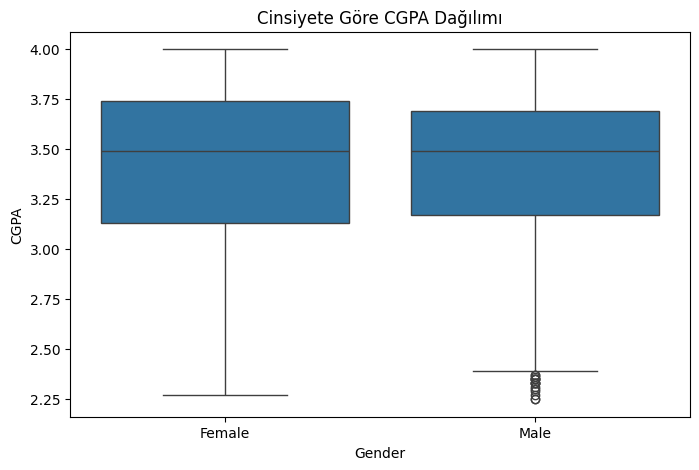

In [30]:
# Cinsiyete göre CGPA karşılaştırması
if 'Gender' in df.columns and 'CGPA' in df.columns:
    genders = df['Gender'].dropna().unique()
    if len(genders) >= 2:
        group1 = df[df['Gender'] == genders[0]]['CGPA'].dropna()
        group2 = df[df['Gender'] == genders[1]]['CGPA'].dropna()

        # Mann-Whitney U Testi
        stat, p_val = stats.mannwhitneyu(group1, group2)
        print(f"Mann-Whitney U Testi Sonucu (CGPA vs Gender):")
        print(f"İstatistik: {stat:.4f}, p-değeri: {p_val:.4e}")

        # Görselleştirme
        plt.figure(figsize=(8, 5))
        sns.boxplot(x='Gender', y='CGPA', data=df)
        plt.title('Cinsiyete Göre CGPA Dağılımı')
        plt.show()
else:
    print("Gerekli sütunlar ('Gender' veya 'CGPA') bulunamadı.")

## 3. İlişki Analizi (Correlation Analysis)
Sayısal değişkenler arasındaki ilişkileri tespit etmek amacıyla Spearman korelasyon matrisi oluşturuyoruz.

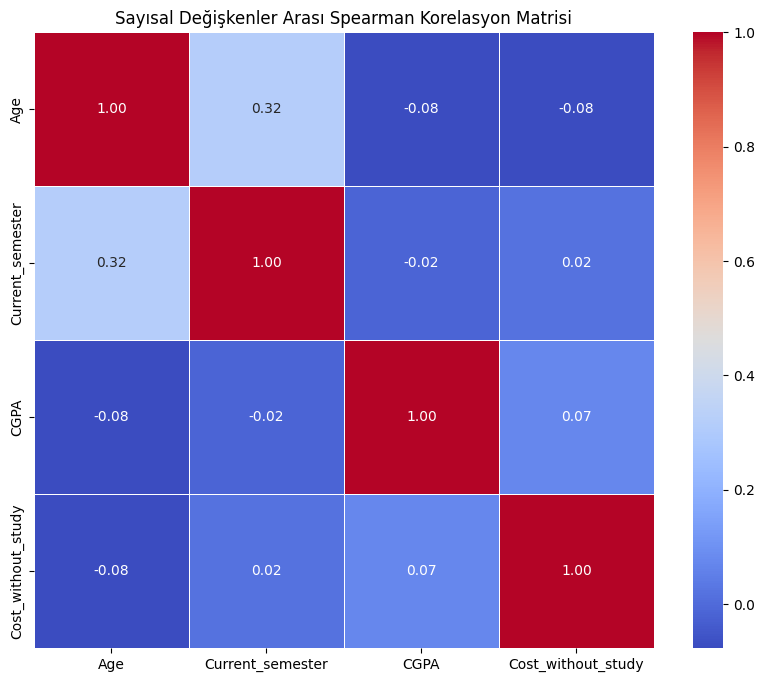

In [29]:
# Sayısal sütunları seçme ve korelasyon hesaplama
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr(method='spearman')

# Isı haritası (Heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Sayısal Değişkenler Arası Spearman Korelasyon Matrisi')
plt.show()